## 01 · Exploratory data analysis and cleaning
We explore train only. The questions we want answered this week:
1. Can we trust the data? (types, hidden missing values, duplicates, impossible values)
2. How imbalanced is churn? (this decides our metrics)
3. Which customers churn, and when? (tenure, contract, price, add-on services)
4. What is it worth? (revenue at risk)
5. Which columns are safe to use as features?

Deeper statistics (confidence intervals, association scores, rule-based baselines, a first tree) wait for the weeks that need them: feature engineering and modelling.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from src.utils.paths import PROCESSED_DIR, RAW_DIR

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)


In [3]:
train_df = pd.read_csv(RAW_DIR / "train.csv")
eval_df = pd.read_csv(RAW_DIR / "eval.csv")


print('train:', train_df.shape, '| eval:', eval_df.shape)


train: (4930, 21) | eval: (1056, 21)


## 1. First look

In [4]:
train_df.head(3)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,6918-UMQCG,Female,0,No,No,5,Yes,No,Fiber optic,No,No,No,No,Yes,No,Month-to-month,No,Electronic check,80.200,384.25,No
1,4140-MUHUG,Female,1,No,No,3,Yes,No,Fiber optic,No,No,Yes,No,Yes,No,Month-to-month,Yes,Electronic check,86.850,220.95,Yes
2,5570-PTWEH,Female,0,Yes,No,3,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Credit card (automatic),75.150,216.75,Yes


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4930 entries, 0 to 4929
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        4930 non-null   str    
 1   gender            4930 non-null   str    
 2   SeniorCitizen     4930 non-null   int64  
 3   Partner           4930 non-null   str    
 4   Dependents        4930 non-null   str    
 5   tenure            4930 non-null   int64  
 6   PhoneService      4930 non-null   str    
 7   MultipleLines     4930 non-null   str    
 8   InternetService   4930 non-null   str    
 9   OnlineSecurity    4930 non-null   str    
 10  OnlineBackup      4930 non-null   str    
 11  DeviceProtection  4930 non-null   str    
 12  TechSupport       4930 non-null   str    
 13  StreamingTV       4930 non-null   str    
 14  StreamingMovies   4930 non-null   str    
 15  Contract          4930 non-null   str    
 16  PaperlessBilling  4930 non-null   str    
 17  Paymen

In [6]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,4930.000,0.161,0.368,0.000,0.000,0.000,0.000,1.000
tenure,4930.000,32.471,24.646,0.000,9.000,29.000,56.000,72.000
MonthlyCharges,4930.000,64.950,30.244,18.400,35.500,70.575,90.050,118.750


In [7]:
train_df.describe(exclude='number').T # type: ignore

,count,unique,top,freq
customerID,4930,4930,6918-UMQCG,1
gender,4930,2,Male,2478
Partner,4930,2,No,2558
Dependents,4930,2,No,3463
PhoneService,4930,2,Yes,4434
MultipleLines,4930,3,No,2347
InternetService,4930,3,Fiber optic,2177
OnlineSecurity,4930,3,No,2439
OnlineBackup,4930,3,No,2142
DeviceProtection,4930,3,No,2140


## 2. Data quality

Never trust a clean-looking info(). We check four things: hidden missing values, duplicates, impossible values, and consistency between columns.

In [8]:
# 2a. Real missing values (NaN)
missing = train_df.isnull().sum()
missing[missing > 0]

Series([], dtype: int64)

In [9]:
# 2b. Hidden missing values: blank strings are NOT counted as NaN by pandas
blank_counts = {C:(train_df[C].astype(str).str.strip() == '').sum() for C in train_df.columns}
{C:n for C,n in blank_counts.items() if n > 0}

{'TotalCharges': np.int64(7)}

## TotalCharges has blank values, which is why pandas read it as text (text) instead of numbers. Before choosing how to fix it, we find out who these customers are.

In [10]:
blank_total = train_df[train_df['TotalCharges'].astype(str).str.strip() == ""]
blank_total[["customerID","tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
42,4075-WKNIU,0,73.350,,No
614,3213-VVOLG,0,25.350,,No
1218,2520-SGTTA,0,20.000,,No
4123,4472-LVYGI,0,52.550,,No
4422,4367-NUYAO,0,25.750,,No
4690,2775-SEFEE,0,61.900,,No
4911,7644-OMVMY,0,19.850,,No


In [11]:
print("Blank TotalCharges rows:", len(blank_total))
print("All of them have tenure == 0:", (blank_total["tenure"] == 0).all())
print("Customers with tenure == 0 in train:", (train_df["tenure"] == 0).sum())

Blank TotalCharges rows: 7
All of them have tenure == 0: True
Customers with tenure == 0 in train: 7


In [12]:
#2c. Check for duplicates
print("fully duplicated rows:", train_df.duplicated().sum())
print("duplicated customerIDs:", train_df["customerID"].duplicated().sum())
print("identical profiles(ignoring ID):", train_df.drop(columns="customerID").duplicated().sum())

fully duplicated rows: 0
duplicated customerIDs: 0
identical profiles(ignoring ID): 9


Identical profiles with different IDs are different customers who happen to have the same plan, so we keep them. We only drop rows that repeat the same CustomerID

In [13]:
# 2d. Impossible values
checks = {
    "tenure < 0": (pd.to_numeric(train_df["tenure"], errors="coerce") < 0).sum(),
    "MonthlyCharges <= 0": (pd.to_numeric(train_df["MonthlyCharges"], errors="coerce") <= 0).sum(),
    "TotalCharges < 0": (pd.to_numeric(train_df["TotalCharges"], errors="coerce") < 0).sum(),
}
checks


{'tenure < 0': np.int64(0),
 'MonthlyCharges <= 0': np.int64(0),
 'TotalCharges < 0': np.int64(0)}

In [14]:
# # 2d. Impossible values
# checks = {
#     "tenure < 0": (train_df["tenure"] < 0).sum(),
#     "MonthlyCharges <= 0": (train_df["MonthlyCharges"] <= 0).sum(),
#     "TotalCharges < 0": (train_df["TotalCharges"] < 0).sum(),
# }
# checks

In [15]:
train_df.nunique().sort_values()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
MultipleLines          3
TechSupport            3
StreamingTV            3
OnlineBackup           3
DeviceProtection       3
StreamingMovies        3
Contract               3
OnlineSecurity         3
InternetService        3
PaymentMethod          4
tenure                73
MonthlyCharges      1448
TotalCharges        4653
customerID          4930
dtype: int64

In [16]:
cat_cols = [
    c for c in train_df.select_dtypes(exclude="number").columns
    if c != "customerID"
]

for col in cat_cols:
    print(f"{col:18s}", sorted(train_df[col].unique()))

gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
TotalCharges       [' ', '100.2', '100.25', '100.35', '100.4', '100.8', '100.9', '1001.2', '1001.5', '1003.05', '1004.5', '1004.75', '1005.7', '1006.9', '1007.8', '1007.9', '1008.55', '1008.7', '1009.25', '101.45', '101

Note the values "No internet service" and "No phone service". They carry the same information as the InternetService / PhoneService columns. We keep this in mind for feature engineering (Week 2).

In [17]:
# 2e. Consistency: TotalCharges should be roughly tenure x MonthlyCharges

expected = train_df["tenure"] * train_df["MonthlyCharges"]
total_charges = pd.to_numeric(train_df["TotalCharges"], errors="coerce")
ratio = (total_charges / expected).replace([np.inf, -np.inf], np.nan)
ratio.describe()

count   4923.000
mean       1.000
std        0.051
min        0.689
25%        0.979
50%        1.000
75%        1.019
max        1.531
dtype: float64

In [18]:
# # 2e. Consistency: TotalCharges should be roughly tenure x MonthlyCharges
# expected = train_df["tenure"] * train_df["MonthlyCharges"]
# ratio = (train_df["TotalCharges"] / expected).replace([np.inf, -np.inf], np.nan)

TotalCharges is close to tenure x MonthlyCharges, so it carries little new information. It does hide one useful signal: average price paid over the lifetime vs the current price (a rise in price can trigger churn). We will test that idea in Week 2.

## 3. The target: how imbalanced is churn?

In [19]:
churn_counts = train_df["Churn"].value_counts()
churn_pct = train_df["Churn"].value_counts(normalize=True) * 100

pd.DataFrame({
    "customers": churn_counts,
    "percent": churn_pct.round(1)
})

,customers,percent
Churn,,
No,3622,73.500
Yes,1308,26.500


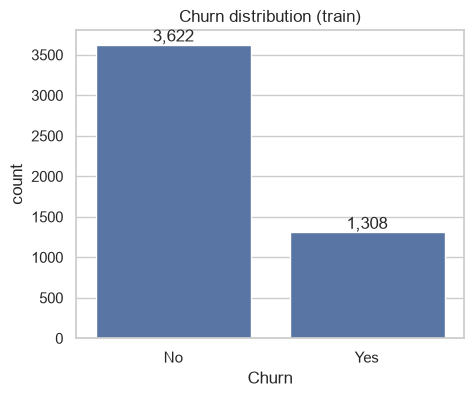

In [20]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=train_df, x="Churn", order=["No", "Yes"], ax=ax)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

ax.set_title("Churn distribution (train)")
plt.show()

In [21]:
majority_accuracy = churn_counts.max() / churn_counts.sum()
print(f"A model that says 'nobody churns' scores {majority_accuracy:.1%} accuracy and 0% recall.")

A model that says 'nobody churns' scores 73.5% accuracy and 0% recall.


Why this matters: a useless model already gets about three quarters accuracy. So we judge models by recall (how many real churners we catch) and precision (how many of our flags were right), and we beat the do-nothing baseline on those, not on accuracy.

In [22]:
# From here on the target is a number: 1 = churned, 0 = stayed
train_df["Churn"] = train_df["Churn"].map({"No": 0, "Yes": 1})
assert train_df["Churn"].notna().all()

base_rate = train_df["Churn"].mean()
status = train_df["Churn"].map({0: "Stayed", 1: "Churned"})  # readable labels for plots
print(f"Overall churn rate: {base_rate:.1%}")

Overall churn rate: 26.5%


## 4. Numeric features

In [23]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
train_df[num_cols] = train_df[num_cols].apply(pd.to_numeric, errors="coerce")

train_df[num_cols].describe().T.assign(skew=train_df[num_cols].skew())

,count,mean,std,min,25%,50%,75%,max,skew
tenure,4930.000,32.471,24.646,0.000,9.000,29.000,56.000,72.000,0.240
MonthlyCharges,4930.000,64.950,30.244,18.400,35.500,70.575,90.050,118.750,-0.220
TotalCharges,4923.000,2305.070,2292.551,18.850,399.800,1389.200,3860.300,8684.800,0.949


In [24]:
# num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
# train_df[num_cols].describe().T.assign(skew=train_df[num_cols].skew())

## Histograms by churn outcome

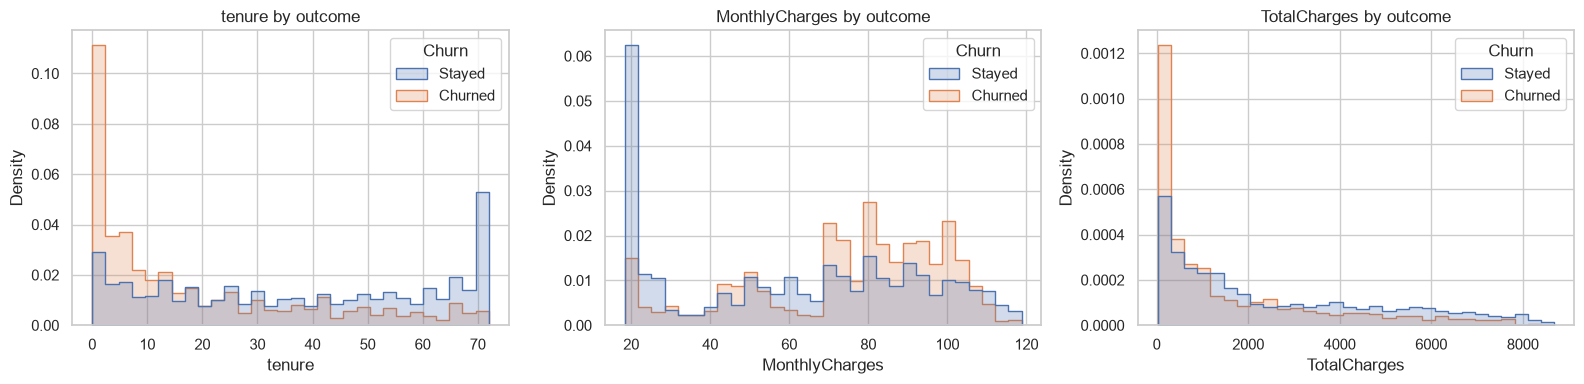

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, num_cols):
    sns.histplot(
        data=train_df,
        x=col,
        hue=status,
        stat="density",
        common_norm=False,
        element="step",
        bins=30,
        ax=ax
    )
    ax.set_title(f"{col} by outcome")

plt.tight_layout()
plt.show()

## Box plots by churn outcome

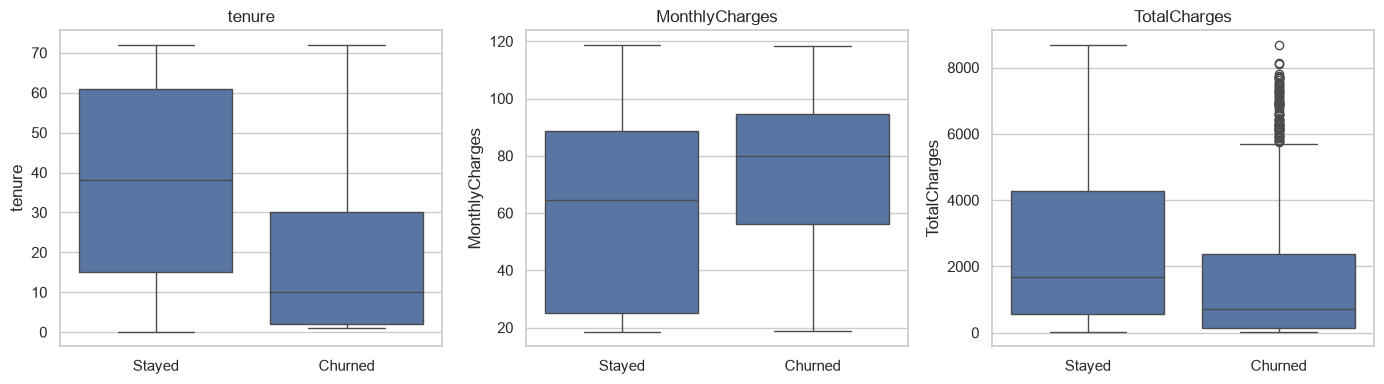

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, num_cols):
    sns.boxplot(
        x=status,
        y=train_df[col],
        order=["Stayed", "Churned"],
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

In [27]:
train_df.groupby("Churn")[num_cols].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.000,64.450,1679.400
1,10.000,80.000,705.075


In [28]:
# Outliers (IQR rule). Do we need to remove any?
for col in num_cols:
    q1, q3 = train_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = (
        (train_df[col] < q1 - 1.5 * iqr)
        | (train_df[col] > q3 + 1.5 * iqr)
    ).sum()
    print(f"{col:15s} outliers: {n_out}")

tenure          outliers: 0
MonthlyCharges  outliers: 0
TotalCharges    outliers: 0


Finding: churners are newer customers who pay more per month. Unlike the housing prices in the reference project, nothing here looks like a data error, so we do not drop any rows.

Two things to notice in the charts:
- tenure has a spike at 72 months for customers who stayed. The data stops at 72, so these are customers still active when the data was taken, not a special group (this is called censoring).
- MonthlyCharges has a big spike near 20, almost all of it stayers. These are phone-only customers with no internet. The price distribution is really a mix of different products, which is why we look at internet type next to price later.
## 5. When do customers leave? (tenure)
Churn is rarely evenly spread over a customer's life. Let us look at churn rate by tenure.

In [29]:
tenure_band = pd.cut(
    train_df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
)

train_df.groupby(tenure_band, observed=True)["Churn"].agg(
    customers="count",
    churn_rate="mean"
)

,customers,churn_rate
tenure,,
0-6,1030,0.522
7-12,507,0.385
13-24,707,0.273
25-48,1118,0.199
49-72,1568,0.101


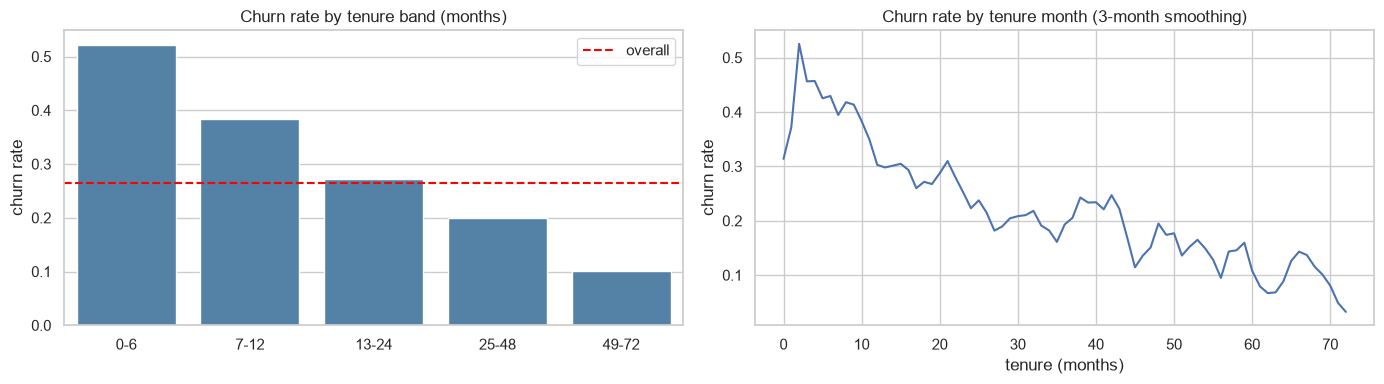

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

band_rate = train_df.groupby(tenure_band, observed=True)["Churn"].mean()
sns.barplot(
    x=band_rate.index.astype(str),
    y=band_rate.values,
    color="steelblue",
    ax=axes[0]
)
axes[0].axhline(base_rate, ls="--", color="red", label="overall")
axes[0].set(
    title="Churn rate by tenure band (months)",
    xlabel="",
    ylabel="churn rate"
)
axes[0].legend()

month_rate = (
    train_df.groupby("tenure")["Churn"]
    .mean()
    .rolling(3, center=True, min_periods=1)
    .mean()
)
axes[1].plot(month_rate.index, month_rate.values)
axes[1].set(
    title="Churn rate by tenure month (3-month smoothing)",
    xlabel="tenure (months)",
    ylabel="churn rate"
)

plt.tight_layout()
plt.show()

Finding: the first year is the danger zone and churn falls steadily as customers stay longer. This tells the business when to intervene (onboarding and the first renewal), not only whom.

# 6. Categorical features: churn rate by level

For every categorical column we compute the churn rate of each level and compare it with the overall rate (dashed red line). SeniorCitizen is stored as 0/1 but is really a category, so we include it.

In [31]:
cat_cols = [
    c for c in train_df.select_dtypes(exclude="number").columns
    if c != "customerID"
] + ["SeniorCitizen"]


def churn_rate_by(col, df=train_df):
    table = df.groupby(col, observed=True)["Churn"].agg(
        customers="count",
        churn_rate="mean"
    )
    table["share_of_customers"] = table["customers"] / len(df)
    return table.sort_values("churn_rate", ascending=False)


churn_rate_by("Contract")

,customers,churn_rate,share_of_customers
Contract,,,
Month-to-month,2704,0.429,0.548
One year,1034,0.109,0.210
Two year,1192,0.030,0.242


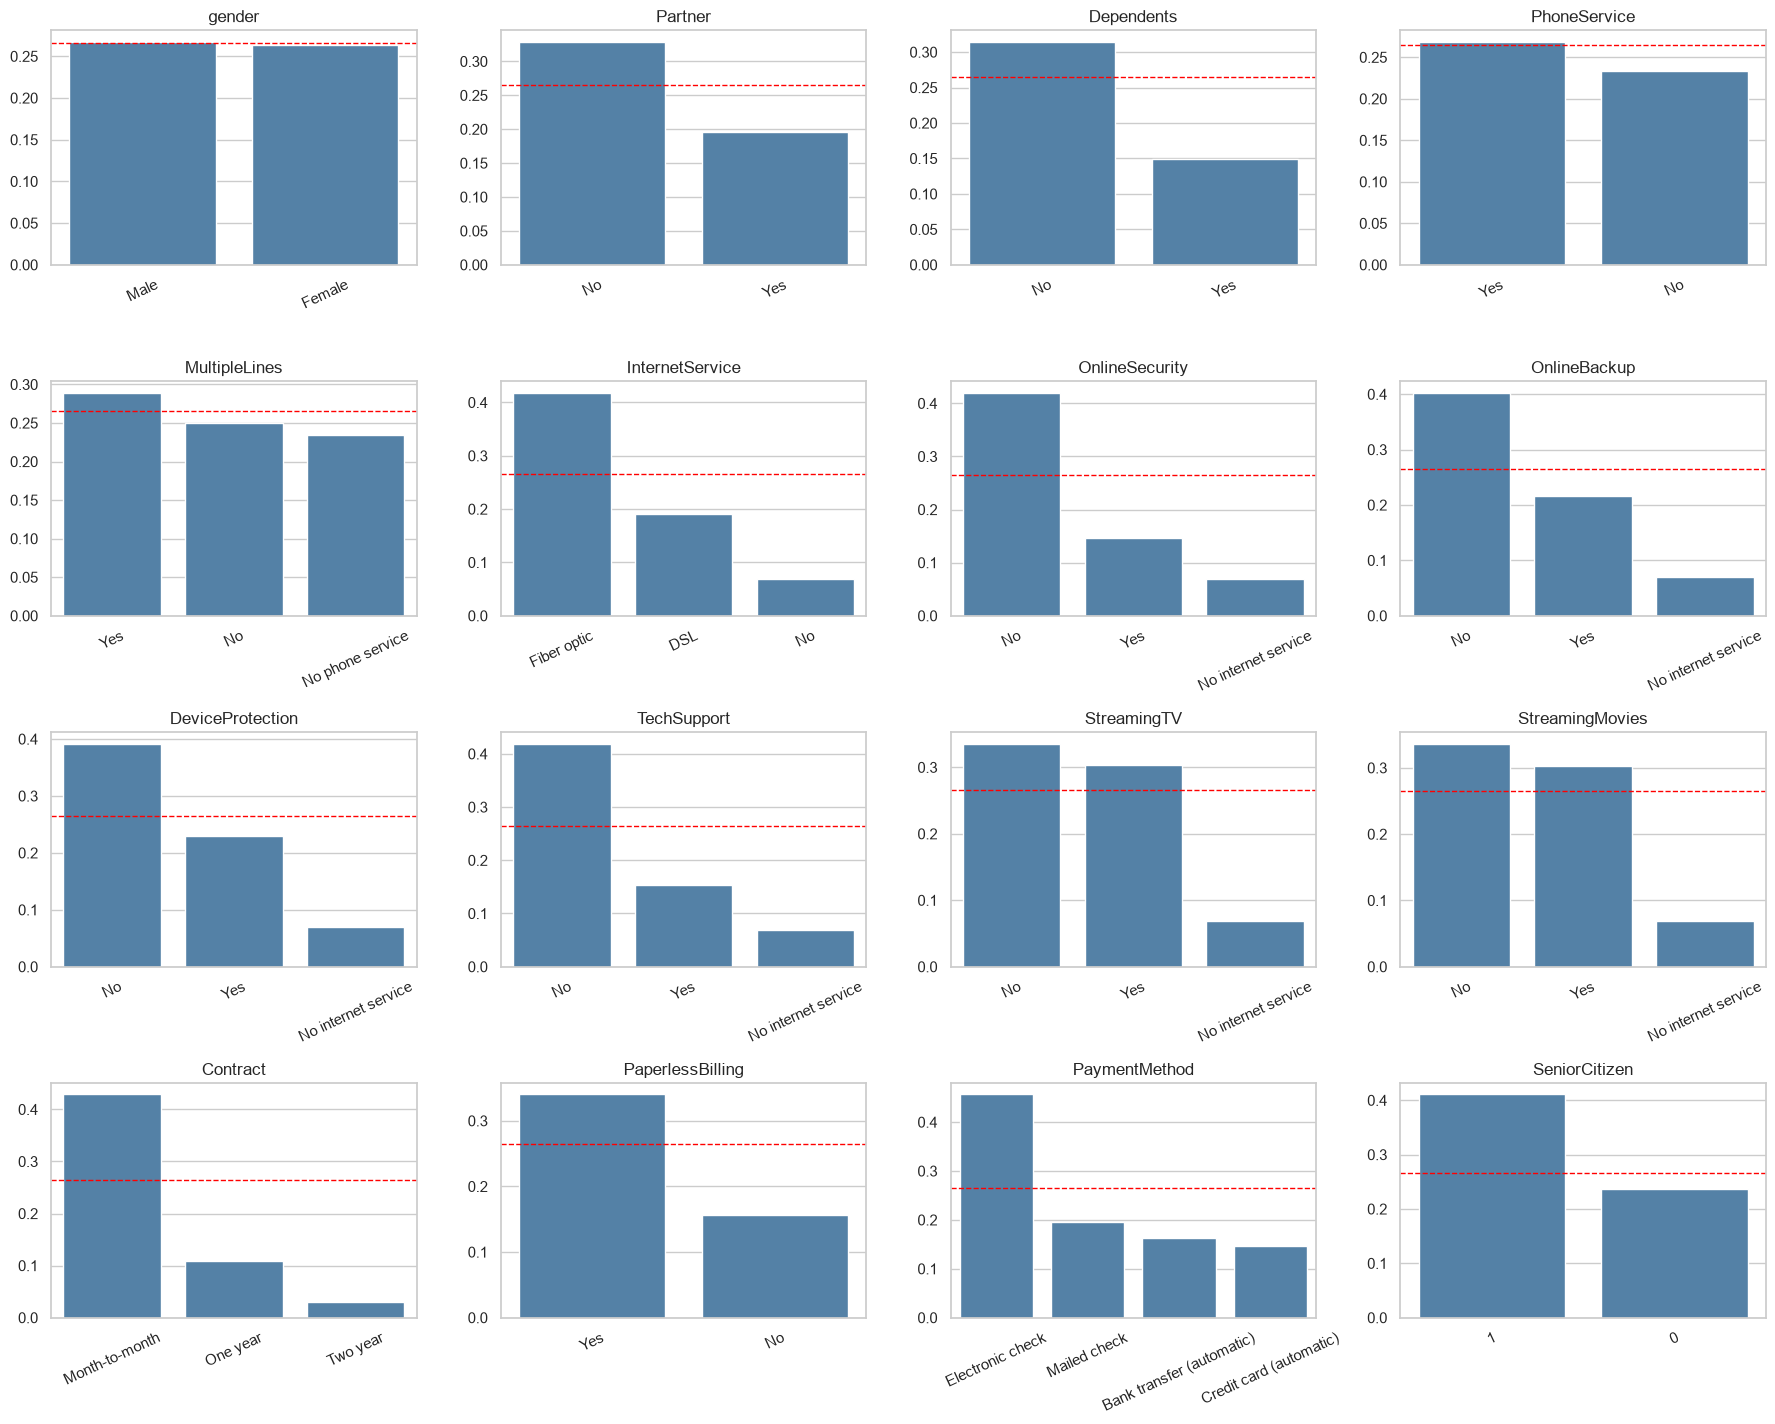

In [32]:
n_cols = 4
n_rows = int(np.ceil(len(cat_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.6 * n_rows))
axes = axes.ravel()

for ax, col in zip(axes, cat_cols):
    table = churn_rate_by(col)
    sns.barplot(
        x=table.index.astype(str).tolist(),
        y=table["churn_rate"].values,
        color="steelblue",
        ax=ax
    )
    ax.axhline(base_rate, ls="--", color="red", lw=1)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)

for ax in axes[len(cat_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [35]:
# Rank features by how much churn rate differs between their levels(levels with >= 30 customers)
rows = []

for col in cat_cols:
    table = churn_rate_by(col)
    table = table[table["customers"] >= 30]
    rows.append({
        "feature": col,
        "levels": len(table),
        "min_rate": table["churn_rate"].min(),
        "max_rate": table["churn_rate"].max(),
        "spread": table["churn_rate"].max() - table["churn_rate"].min()
    })

pd.DataFrame(rows).sort_values(
    "spread", ascending=False
).reset_index(drop=True)

,feature,levels,min_rate,max_rate,spread
0,Contract,3,0.030,0.429,0.398
1,OnlineSecurity,3,0.069,0.420,0.351
2,TechSupport,3,0.069,0.419,0.350
3,InternetService,3,0.069,0.418,0.349
4,OnlineBackup,3,0.069,0.403,0.334
5,DeviceProtection,3,0.069,0.392,0.323
6,PaymentMethod,4,0.147,0.456,0.309
7,StreamingMovies,3,0.069,0.337,0.267
8,StreamingTV,3,0.069,0.336,0.266
9,PaperlessBilling,2,0.157,0.340,0.183


Finding: Contract, OnlineSecurity, TechSupport, InternetService and PaymentMethod separate churners from stayers the most. gender barely matters, which is a useful (and fairer) result. Demographics are weak signals compared with how the customer buys and uses the service.

# 7. Digging into the business story

A good analyst does not stop at single columns. We test a few specific hypotheses.

# H1. Contract and tenure interact

Month-to-month customers can leave any time. Does contract still matter once a customer has stayed a while?

<Axes: xlabel='tenure_band', ylabel='Contract'>

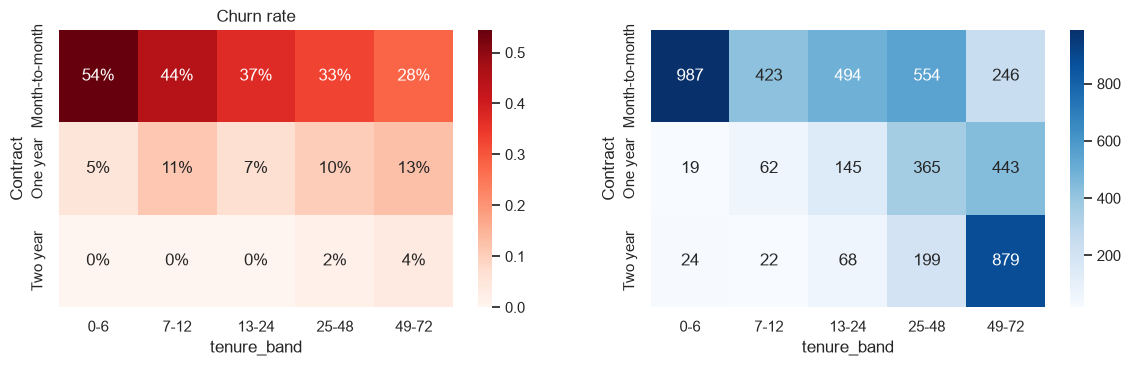

In [34]:
pivot_rate = (
    train_df.assign(tenure_band=tenure_band)
    .pivot_table(
        index="Contract",
        columns="tenure_band",
        values="Churn",
        aggfunc="mean",
        observed=True
    )
)

pivot_n = (
    train_df.assign(tenure_band=tenure_band)
    .pivot_table(
        index="Contract",
        columns="tenure_band",
        values="Churn",
        aggfunc="count",
        observed=True
    )
)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
sns.heatmap(pivot_rate, annot=True, fmt=".0%", cmap="Reds", ax=axes[0])
axes[0].set_title("Churn rate")
sns.heatmap(pivot_n, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])

# H2. Do more add-on services mean fewer cancellations?

In [36]:
# Only customers with internet can have these add-ons
internet = train_df[train_df["InternetService"] != "No"]

protect_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
addon_cols = protect_cols + ["StreamingTV", "StreamingMovies"]

In [37]:
# How does churn change with the NUMBER of add-ons a customer has?
addon_cols = protect_cols + ["StreamingTV", "StreamingMovies"]
addon_count = internet[addon_cols].eq("Yes").sum(axis=1)

internet.groupby(addon_count)["Churn"].agg(
    customers="count",
    churn_rate="mean"
)

,customers,churn_rate
0,470,0.511
1,658,0.467
2,733,0.371
3,773,0.274
4,612,0.230
5,399,0.130
6,217,0.046


# H3. Price: is it the price, or the product?

In [38]:
price_band = pd.qcut(train_df["MonthlyCharges"], 5)

(
    train_df.groupby([price_band, "InternetService"], observed=True)["Churn"]
    .agg(customers="count", churn_rate="mean")
    .unstack("InternetService")
)

customers                     churn_rate  \
InternetService                  DSL Fiber optic      No        DSL   
MonthlyCharges                                                        
(18.398999999999997, 25.1]    38.000         NaN 957.000      0.421   
(25.1, 58.93]                866.000         NaN 111.000      0.281   
(58.93, 79.35]               564.000     426.000     NaN      0.096   
(79.35, 94.45]               216.000     768.000     NaN      0.046   
(94.45, 118.75]                1.000     983.000     NaN      0.000   

                                              
InternetService            Fiber optic    No  
MonthlyCharges                                
(18.398999999999997, 25.1]         NaN 0.074  
(25.1, 58.93]                      NaN 0.027  
(58.93, 79.35]                   0.542   NaN  
(79.35, 94.45]                   0.460   NaN  
(94.45, 118.75]                  0.333   NaN

Compare the same price band across internet types. In the bands where both DSL and Fiber exist, Fiber customers churn many times more than DSL customers paying the same price. So the problem is not simply "Fiber is expensive". It points to service quality, installation or support problems, or the type of customer Fiber attracts. That is a question for the business, not for the model.

Careful: DSL and Fiber barely overlap in price (Fiber starts around 60), so the small cells at the edges mean little. Always read counts next to rates.

# 8. What is churn worth? (revenue view)

Counting customers treats everyone equally, but a lost customer who pays 100 a month costs more than one who pays 20.

In [39]:
by_outcome = train_df.groupby("Churn")["MonthlyCharges"].agg(
    customers="count",
    monthly_revenue="sum",
    avg_monthly="mean"
)
by_outcome

,customers,monthly_revenue,avg_monthly
Churn,,,
0,3622,222102.200,61.320
1,1308,98101.700,75.001


In [40]:
lost = by_outcome.loc[1, "monthly_revenue"]
total = by_outcome["monthly_revenue"].sum()

print(f"Customer churn rate: {base_rate:.1%}")
print(f"Revenue churn rate : {lost / total:.1%}  (monthly revenue of churners / total monthly revenue)")
print(f"Monthly revenue lost in this sample: {lost:,.0f}")

Customer churn rate: 26.5%
Revenue churn rate : 30.6%  (monthly revenue of churners / total monthly revenue)
Monthly revenue lost in this sample: 98,102


In [41]:
segments = (
    train_df.assign(
        revenue_lost=train_df["MonthlyCharges"] * train_df["Churn"]
    )
    .groupby("Contract")
    .agg(
        customers=("Churn", "size"),
        churn_rate=("Churn", "mean"),
        monthly_revenue=("MonthlyCharges", "sum"),
        monthly_revenue_lost=("revenue_lost", "sum")
    )
)

segments["share_of_revenue_lost"] = (
    segments["monthly_revenue_lost"]
    / segments["monthly_revenue_lost"].sum()
)

segments.sort_values("monthly_revenue_lost", ascending=False)

,customers,churn_rate,monthly_revenue,monthly_revenue_lost,share_of_revenue_lost
Contract,,,,,
Month-to-month,2704,0.429,180110.550,85456.300,0.871
One year,1034,0.109,67562.950,9518.350,0.097
Two year,1192,0.030,72530.400,3127.050,0.032


Finding: revenue churn is higher than customer churn, because the customers who leave pay more per month than the average customer. This is what we will use later to choose a decision threshold with a retention budget.

# 9. Is every column safe to use as a feature?

Ask of each column: will we know this at prediction time, before the customer leaves?



No column describes what happened after the customer left (such as a cancellation reason or a retention score), so there is no target leakage.

# 10. Apply the cleaning and save

In [42]:
def clean(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # strip stray whitespace in text columns
    text_cols = df.select_dtypes(exclude="number").columns
    df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())

    # TotalCharges: text -> number; blank means a brand-new customer (tenure 0) -> 0
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    new_customer = df["tenure"] == 0
    df.loc[new_customer, "TotalCharges"] = (
        df.loc[new_customer, "TotalCharges"].fillna(0.0)
    )

    # same customer twice -> keep one
    df = df.drop_duplicates(subset="customerID")

    # target to 0/1
    if not pd.api.types.is_numeric_dtype(df["Churn"]):
        df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

    return df

In [43]:
clean_train = clean(pd.read_csv(RAW_DIR / "train.csv"))
clean_eval = clean(pd.read_csv(RAW_DIR / "eval.csv"))

for name, part in [("train", clean_train), ("eval", clean_eval)]:
    assert part.isna().sum().sum() == 0, f"{name} still has missing values"
    assert part["Churn"].isin([0, 1]).all()
    print(f"{name:6s} {part.shape}  churn rate={part['Churn'].mean():.1%}")

train  (4930, 21)  churn rate=26.5%
eval   (1056, 21)  churn rate=26.5%


In [44]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

clean_train.to_csv(PROCESSED_DIR / "cleaning_train.csv", index=False)
clean_eval.to_csv(PROCESSED_DIR / "cleaning_eval.csv", index=False)

print("✅ Cleaning complete.")

✅ Cleaning complete.


# Summary of findings (train split, 4,930 customers)

- Imbalance: 26.5% of customers churn. A model that predicts "nobody churns" scores 73.5% accuracy and catches no one, so we judge models by recall and precision, not accuracy.
- Data quality: the only real problem is TotalCharges, blank for brand-new customers (tenure 0), fixed with 0. No duplicate customers and no outliers to drop.
- When they leave: churn falls steadily with tenure, from about 52% in months 0 to 6 to about 10% after four years. The first year is the danger zone.
- Who churns: month-to-month contracts (43%, against 11% for one year and 3% for two years), Fiber optic internet, electronic-check payment, and customers with few or no add-on services (about 51% with none, about 5% with all six).
- Fiber is not just a price problem: at the same monthly price, Fiber customers churn far more than DSL customers, which points to service quality.
- What does not matter: gender and PhoneService.
- Money: churners pay more per month, so revenue churn (30.6%) is worse than customer churn (26.5%). 87% of the lost monthly revenue sits in month-to-month contracts.
- Cleaning: one clean() function, applied to train and eval, saved to data/processed/.
- Honest limits: this is a snapshot, so we can show association, not cause, and we cannot split by time.

Coming in later weeks (we will use the cleaned files from today): which features are most strongly linked to churn and how sure we are (Week 2), a simple rules-based baseline the model must beat (Week 3), and what a first decision tree sees (Week 4).